# 03 · Entorno semi-Markov y gestor de posiciones

Notebook de demostración de la parte 03 (`code/env.py`). Solo importa funciones de los módulos y muestra resultados.
Guía: `docs/instrucciones/03_entorno.md`; notas: `docs/notas_clase/02_rl_q_learning_gymnasium.md` y `03_sb3_dqn_ppo.md`.

In [1]:
import sys
sys.path.insert(0, "..")
sys.modules.pop("code", None)  # IPython ya importó el módulo `code` estándar (ver docs/decisiones.md)

import warnings
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from stable_baselines3.common.env_checker import check_env

from code import data, env
from main import BTC_CSV, FOLDS

ohlcv, _ = data.load_ohlcv(BTC_CSV)
fold = data.build_fold_dataset(ohlcv, data.compute_features(ohlcv), 1, FOLDS[1])
net_log = lambda outcome: outcome.net_log_return   # contribución provisional; la definitiva es la de code/reward.py (parte 04)

## 1. Las piezas del entorno (S19)

| pieza | en este entorno |
|---|---|
| `action_space` | `Discrete(3)`: 0 esperar una barra, 1 abrir largo, 2 abrir corto (el agente solo decide estando plano) |
| `observation_space` | `Box(−5, 5)`: 22 features normalizadas de la barra de decisión + 3 del estado de la cuenta |
| `reset` | inicio aleatorio con `self.np_random` (entrenamiento) o el principio de la partición (evaluación) |
| `step` | llena en la apertura de t + 1 y el gestor cierra por stop, take-profit, horizonte o fin de datos; τ en `info` |
| `terminated` / `truncated` | ruina (capital < 50 %, solo al entrenar) / fin del episodio o de los datos |

In [2]:
trading_env = env.make_env(fold, "train", net_log)
print("acciones:", trading_env.action_space, "· observación:", trading_env.observation_space)
with warnings.catch_warnings():
    warnings.simplefilter("error")
    check_env(trading_env, warn=True)
print("check_env: OK, sin advertencias")

acciones: Discrete(3) · observación: Box(-5.0, 5.0, (25,), float32)
check_env: OK, sin advertencias


## 2. Una operación, paso a paso

Barreras a k·σ̂·√H del precio de entrada con σ̂ = volatilidad EWMA de 24 h al decidir (H = 24 h, k = 1).
Se abre un largo en una época de decisión de la validación y se grafica la trayectoria hasta el cierre.

In [3]:
demo = env.make_env(fold, "validation", net_log, mode="eval")
demo.reset(seed=0)
for _ in range(200):
    demo.step(env.WAIT)                       # avanza 200 barras sin operar
_, reward, _, _, info = demo.step(env.LONG)
{k: info[k] for k in ["decision_time", "entry_time", "exit_time", "entry_price", "stop_level", "take_level",
                      "exit_price", "exit_reason", "duration_hours", "net_pnl", "intrabar_ambiguous"]} | {"duration (τ, h)": info["duration"], "reward": reward}

{'decision_time': Timestamp('2022-01-09 08:00:00+0000', tz='UTC'),
 'entry_time': Timestamp('2022-01-09 09:00:00+0000', tz='UTC'),
 'exit_time': Timestamp('2022-01-10 08:00:00+0000', tz='UTC'),
 'entry_price': np.float64(41666.66),
 'stop_level': np.float64(40293.34253766191),
 'take_level': np.float64(43039.977462338094),
 'exit_price': np.float64(41816.84),
 'exit_reason': 'horizonte',
 'duration_hours': np.float64(24.0),
 'net_pnl': np.float64(0.0010998151759702601),
 'intrabar_ambiguous': False,
 'duration (τ, h)': 24.0,
 'reward': 0.0010992108223372048}

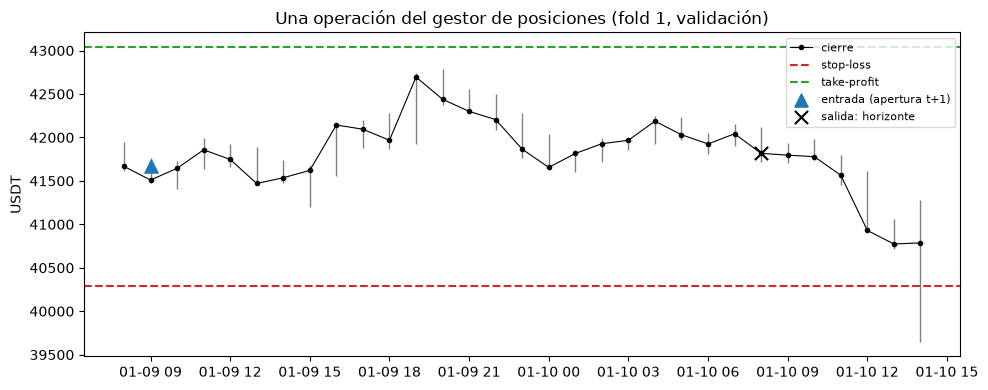

In [4]:
bars = demo_bars = fold.ohlcv["validation"].loc[info["decision_time"]: info["exit_time"] + pd.Timedelta(hours=6)]
fig, ax = plt.subplots(figsize=(10, 4))
ax.vlines(bars.index, bars["low"], bars["high"], color="grey", lw=1)
ax.plot(bars.index, bars["close"], "k.-", lw=0.8, label="cierre")
ax.axhline(info["stop_level"], color="tab:red", ls="--", label="stop-loss")
ax.axhline(info["take_level"], color="tab:green", ls="--", label="take-profit")
ax.scatter([info["entry_time"]], [info["entry_price"]], marker="^", s=90, color="tab:blue", zorder=3, label="entrada (apertura t+1)")
ax.scatter([info["exit_time"]], [info["exit_price"]], marker="x", s=90, color="k", zorder=3, label=f"salida: {info['exit_reason']}")
ax.set_title("Una operación del gestor de posiciones (fold 1, validación)"); ax.set_ylabel("USDT"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

## 3. Validar antes de entrenar: líneas base con costos

Si el agente aleatorio ganara dinero, el simulador tendría un error. Con 0.125 % por lado, operar sin información
pierde: el costo de ida y vuelta (≈ 25 pb) es mucho mayor que el rendimiento bruto medio de una operación al azar.

In [5]:
def run(policy, split="train", seed=0):
    e = env.make_env(fold, split, net_log, mode="eval")
    e.reset(seed=seed)
    rng, done = np.random.default_rng(seed), False
    while not done:
        _, _, terminated, truncated, _ = e.step(rng.integers(3) if policy is None else policy)
        done = terminated or truncated
    return e

rows = []
for name, policy in [("aleatorio", None), ("siempre largo", env.LONG), ("siempre plano", env.WAIT)]:
    e = run(policy)
    log = e.trade_log()
    rows.append({"política": name, "capital final": e.equity, "operaciones": len(log),
                 "P&L bruto": log["gross_pnl"].sum() if len(log) else 0.0, "costos": log["costs"].sum() if len(log) else 0.0})
pd.DataFrame(rows).round(4)

,política,capital final,operaciones,P&L bruto,costos
0,aleatorio,0.0008,2174,0.1650,1.1642
1,siempre largo,0.0060,2254,0.9082,1.9022
2,siempre plano,1.0000,0,0.0000,0.0000


In [6]:
e = run(None)
log = e.trade_log()
print(log["exit_reason"].value_counts(normalize=True).round(3))
print("operaciones con stop y take-profit en la misma barra:", f"{100 * log['intrabar_ambiguous'].mean():.2f} %")
log[["entry_time", "exit_time", "side", "exit_reason", "entry_price", "exit_price", "gross_pnl", "costs", "net_pnl"]].head()

exit_reason
horizonte      0.435
take_profit    0.283
stop           0.282
fin_datos      0.000
Name: proportion, dtype: float64
operaciones con stop y take-profit en la misma barra: 0.09 %


,entry_time,exit_time,side,exit_reason,entry_price,exit_price,gross_pnl,costs,net_pnl
0,2017-09-16 12:00:00+00:00,2017-09-17 11:00:00+00:00,corto,horizonte,3630.06,3499.030000,0.036096,0.002455,0.033641
1,2017-09-17 12:00:00+00:00,2017-09-18 06:00:00+00:00,largo,take_profit,3499.03,3926.002391,0.126131,0.002742,0.123389
2,2017-09-18 07:00:00+00:00,2017-09-19 06:00:00+00:00,largo,horizonte,3950.01,3964.920000,0.004367,0.002898,0.001469
3,2017-09-19 13:00:00+00:00,2017-09-20 12:00:00+00:00,corto,horizonte,4016.48,3912.160000,0.030090,0.002859,0.027231
4,2017-09-20 13:00:00+00:00,2017-09-21 12:00:00+00:00,largo,horizonte,3929.23,3858.080000,-0.021471,0.002937,-0.024409


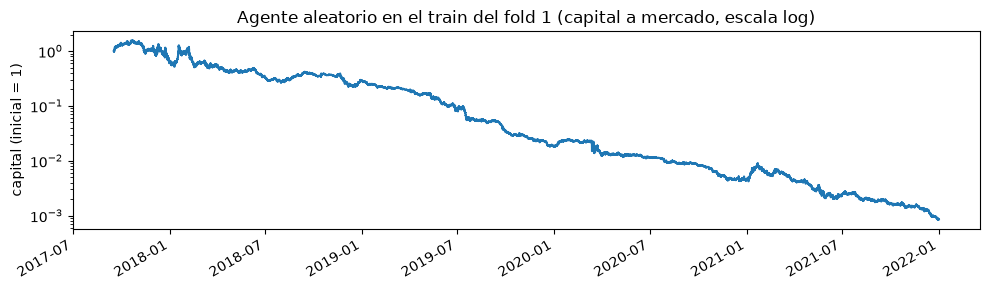

In [7]:
ax = e.equity_series().plot(figsize=(10, 3), logy=True, title="Agente aleatorio en el train del fold 1 (capital a mercado, escala log)")
ax.set_ylabel("capital (inicial = 1)"); ax.set_xlabel(""); plt.tight_layout(); plt.show()